# Module 1 — Potential Outcomes Framework

Part of the Causal Inference Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- "The effect of the program" sounds clear, but it has no fixed meaning until you say *for whom* and *compared with what*. Potential outcomes is the notation that pins it down.
- Module 1 explains what we are trying to measure: how much a job-training program raised the earnings of the men who took it. It also shows why simply comparing them with men who did not take it gives the wrong answer. Modules 2–10 are the methods that measure it.
- **Recap + pointer:** the counterfactual idea and a confounded-vs-randomized simulation are already in [A/B Testing Playbook, Module 1](https://github.com/omri-sabag83/A-B-Testing-Playbook/blob/main/01_foundations_causal_inference.ipynb). This module does not rebuild them. It adds the formal notation, the estimands (estimand = the exact number you are trying to estimate) and the decomposition (decomposition = splitting the earnings gap between the men who took the program and the men who did not into two parts: the real effect of the program, plus how different the two groups were to begin with), on real numbers.

**What this module produces:**
1. A six-person table where both outcomes are known, with the ATE (average treatment effect), ATT (average treatment effect on the treated) and ATC (average treatment effect on the controls) computed exactly.
2. The decomposition "naive difference = effect + selection bias", derived line by line. Selection bias = how different the two groups would have been even with no treatment at all.
3. The same decomposition on real data from the NSW (National Supported Work) Demonstration, a 1970s US job-training program. Here selection bias can be estimated directly: (−$16,999.1).

## From the curriculum

> ## <u>Module 1 — Potential Outcomes Framework</u>
>
> **Overlap:** recap + pointer. The counterfactual idea and a confounded vs
> randomized simulation are in
> [A/B Testing Playbook, Module 1](https://github.com/omri-sabag83/A-B-Testing-Playbook/blob/main/01_foundations_causal_inference.ipynb).
> This module adds the formal notation and puts real numbers on it.
>
> **Concepts**
> - Potential outcomes Y(1) and Y(0), the individual effect, and the
>   fundamental problem: only one of the two is ever observed
> - Estimands: ATE (average treatment effect), ATT (average treatment effect on
>   the treated), ATC (average treatment effect on the controls), and why they
>   differ when effects vary
> - The decomposition: naive difference = ATT + selection bias, derived line by
>   line
> - Why randomization sets selection bias to zero on average
> - Without randomization, two assumptions take its place:
>   1. Unconfoundedness: men who looked the same before the program would have
>      earned the same without it, whether they took it or not.
>   2. Overlap: for every man who took the program, there are men who did not
>      take it and who looked like him before.
> - SUTVA (stable unit treatment value assumption): no interference, one version
>   of the treatment
>
> **Why it matters**
> Every later module is a different way to estimate the one missing potential
> outcome. Without this notation, "the effect" has no fixed meaning, and a
> method's assumptions cannot be stated.
>
> **Worked example**
> 1. A six-person table where both outcomes are known (chosen example): ATE,
>    ATT, ATC and the decomposition computed exactly.
> 2. The NSW (National Supported Work) job-training data: the experiment
>    estimates the ATT at $1,794.3. The naive comparison against the PSID
>    (Panel Study of Income Dynamics) group gives (−$15,204.8). The difference,
>    (−$16,999.1), is selection bias, estimated directly.
> 3. Overlap for the ATT: 14 PSID men share the profile of 82 treated men
>    (zero 1975 earnings, unmarried, black).
>
> **Resources**
> - [Causal Inference: The Mixtape, ch. 4 "Potential Outcomes Causal Model"](https://mixtape.scunning.com/04-Potential_Outcomes_and_Randomization.html)
>   (Scott Cunningham, ~45 min, verified): the notation, the decomposition and SUTVA.
> - [The Effect, ch. 10 "Treatment Effects"](https://theeffectbook.net/ch-TreatmentEffects.html)
>   (Nick Huntington-Klein, ~30 min, verified): ATE vs ATT and heterogeneous effects.
> - [NSW data page](https://users.nber.org/~rdehejia/nswdata2.html) (Rajeev
>   Dehejia, verified): the data source, its licence and the papers to cite.
>
> **Exercise type:** redo the decomposition with the CPS (Current Population Survey,
> a monthly US labour survey) comparison group.
> Fully worked.
>
> **Interview angle:** "Users who adopted feature X retain better. Did X cause
> it?"

## Recap: what the A/B Testing Playbook already showed

[Module 1 of the A/B Testing Playbook](https://github.com/omri-sabag83/A-B-Testing-Playbook/blob/main/01_foundations_causal_inference.ipynb) simulated push notifications with a true effect of zero:
- Without randomization (each user decided whether to switch notifications on, and keener users switched them on more often): 36.84% of users who switched notifications on kept using the app, vs 23.65% of users who did not. That gap of 13.2 percentage points looks like an effect of notifications, but it only reflects who switched them on.
- Randomized comparison (a coin flip decides): 0.285614 for the prompted group vs 0.285586 for the others. That is a lift of 0.00003, which rounds to 0.0.

**In this module's terms:** the 13.2 points were all selection bias, and the effect was 0. The rest of this module gives that sentence its formal meaning.

## Lesson

### Potential outcomes: two numbers per person

For each person *i* and a yes/no treatment (here: joining NSW, a US job-training program that gave men with very low earnings supervised work and training):
- **Y<sub>i</sub>(1)** = the outcome person *i* would have **if treated**.
- **Y<sub>i</sub>(0)** = the outcome the same person would have **if not treated**.
- **The individual effect** = Y<sub>i</sub>(1) − Y<sub>i</sub>(0).

Both are possible results, defined before treatment is decided. Treatment only decides which one actually happens and gets recorded. T<sub>i</sub> = 1 if treated, 0 if not, and the observed outcome is:

> Y<sub>i</sub> = T<sub>i</sub> × Y<sub>i</sub>(1) + (1 − T<sub>i</sub>) × Y<sub>i</sub>(0)

If T<sub>i</sub> = 1, the second term is 0 and we see Y<sub>i</sub>(1). If T<sub>i</sub> = 0, the first term is 0 and we see Y<sub>i</sub>(0).

### The fundamental problem

For every person, one of the two potential outcomes is missing. So no individual effect can ever be computed from data. Causal inference gives up on individuals and estimates **averages** instead, and every method in this playbook is a different way to stand in for the missing half.

### Three averages: ATE, ATT, ATC

| Estimand | In words | Formula |
|---|---|---|
| ATE (average treatment effect) | the effect averaged over **everyone** | E[Y(1) − Y(0)] |
| ATT (average treatment effect on the treated) | the effect averaged over **those who were treated** | E[Y(1) − Y(0) \| T = 1] |
| ATC (average treatment effect on the controls) | the effect averaged over **those who were not treated** | E[Y(1) − Y(0) \| T = 0] |

E[ ] means "the average of". "\| T = 1" means "among people with T = 1".

If the treated and the untreated would gain the same on average, the three averages are the same. If one group would gain more, the three differ, and which one you need depends on the question you are asking:
- "Did the program help the people who joined it?" → ATT. This is the NSW question.
- "What if we enrolled everyone?" → ATE.
- "What if we extended it to people who did not join?" → ATC.

## Worked example 1: six people, both outcomes known

**Chosen example** (not data), because only invented numbers can show both potential outcomes at once. The numbers echo the NSW setting, where low earners join the program. In this invented example, the program also helps the joiners more than the others. That part is invented: the NSW data cannot show it.

Outcomes are yearly earnings in $ thousands.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import common
from common import show, BLUE, ORANGE, GREY

toy = pd.DataFrame({
    "person": list("ABCDEF"),
    "Y(0) if not treated": [2, 3, 1, 20, 18, 22],
    "Y(1) if treated": [5, 5, 4, 21, 19, 22],
    "T treated?": [1, 1, 1, 0, 0, 0],
})
toy["effect Y(1) - Y(0)"] = toy["Y(1) if treated"] - toy["Y(0) if not treated"]
toy["Y observed"] = np.where(toy["T treated?"] == 1, toy["Y(1) if treated"], toy["Y(0) if not treated"])
show(toy)

person  Y(0) if not treated  Y(1) if treated  T treated?  effect Y(1) - Y(0)  Y observed
A                         2                5           1                   3           5
B                         3                5           1                   2           5
C                         1                4           1                   3           4
D                        20               21           0                   1          20
E                        18               19           0                   1          18
F                        22               22           0                   0          22


In [2]:
treated, control = toy[toy["T treated?"] == 1], toy[toy["T treated?"] == 0]
ate = toy["effect Y(1) - Y(0)"].mean()
att = treated["effect Y(1) - Y(0)"].mean()
atc = control["effect Y(1) - Y(0)"].mean()
print("The three averages (only possible because both outcomes are known):")
print(f"  ATE = average effect of all 6 = (3 + 2 + 3 + 1 + 1 + 0) / 6 = {ate:.3f}")
print(f"  ATT = average effect of the 3 treated = (3 + 2 + 3) / 3 = {att:.3f}")
print(f"  ATC = average effect of the 3 untreated = (1 + 1 + 0) / 3 = {atc:.3f}")

The three averages (only possible because both outcomes are known):
  ATE = average effect of all 6 = (3 + 2 + 3 + 1 + 1 + 0) / 6 = 1.667
  ATT = average effect of the 3 treated = (3 + 2 + 3) / 3 = 2.667
  ATC = average effect of the 3 untreated = (1 + 1 + 0) / 3 = 0.667


**Observation:** the three averages differ (2.667, 1.667, 0.667) because the people who joined gain a different amount on average (2.667) than the people who did not join (0.667). For that to happen, the effect must differ from person to person, but that alone is not enough: the two groups' averages must also differ.

### What the data would actually show

In real data, the "Y(0)" column is missing for A, B, C and the "Y(1)" column is missing for D, E, F. All we can compute is the **naive difference**: the average observed outcome of the treated minus that of the untreated.

In [3]:
naive = treated["Y observed"].mean() - control["Y observed"].mean()
print(f"Treated, average observed = (5 + 5 + 4) / 3 = {treated['Y observed'].mean():.3f}")
print(f"Untreated, average observed = (20 + 18 + 22) / 3 = {control['Y observed'].mean():.3f}")
print(f"Naive difference = {treated['Y observed'].mean():.3f} - {control['Y observed'].mean():.3f} = {naive:.3f}")

Treated, average observed = (5 + 5 + 4) / 3 = 4.667
Untreated, average observed = (20 + 18 + 22) / 3 = 20.000
Naive difference = 4.667 - 20.000 = -15.333


The naive difference says the program **cut** earnings by 15.333. In this scenario, a real analyst could not tell this is wrong (we can, because we still have the full table outside this scenario). The next part explains exactly where the (−15.333) comes from.

### The decomposition, derived

A decomposition splits one number into parts that add up to it. Here the number is the naive difference, (−15.333), and it splits into two parts: the real effect of the program, plus how different the two groups were to begin with.

Start from the naive difference, written with potential outcomes. For the treated we observe Y(1), for the untreated we observe Y(0):

> naive = E[Y(1) | T = 1] − E[Y(0) | T = 0]

Now subtract and add the same number, E[Y(0) | T = 1]: what the **treated** would have earned **without** treatment. Subtracting and adding the same number changes nothing:

> naive = E[Y(1) | T = 1] − E[Y(0) | T = 1] + E[Y(0) | T = 1] − E[Y(0) | T = 0]

Group the first two terms and the last two terms:

> naive = ( E[Y(1) | T = 1] − E[Y(0) | T = 1] ) + ( E[Y(0) | T = 1] − E[Y(0) | T = 0] )

- The first bracket is the average effect among the treated: **the ATT**.
- The second bracket compares the two groups **with no treatment at all**: how different they already were. This is **selection bias**.

> **naive difference = ATT + selection bias**

The decomposition is always true, for any data. Below it is checked on the six people.

In [4]:
y0_treated = treated["Y(0) if not treated"].mean()
y0_control = control["Y(0) if not treated"].mean()
selection_bias = y0_treated - y0_control
print(f"E[Y(0) | T = 1], the treated without treatment = (2 + 3 + 1) / 3 = {y0_treated:.3f}")
print(f"E[Y(0) | T = 0], the untreated without treatment = (20 + 18 + 22) / 3 = {y0_control:.3f}")
print(f"Selection bias = {y0_treated:.3f} - {y0_control:.3f} = {selection_bias:.3f}")
print()
print(f"ATT + selection bias = {att:.3f} + ({selection_bias:.3f}) = {att + selection_bias:.3f}")
print(f"Naive difference = {naive:.3f}")

E[Y(0) | T = 1], the treated without treatment = (2 + 3 + 1) / 3 = 2.000
E[Y(0) | T = 0], the untreated without treatment = (20 + 18 + 22) / 3 = 20.000
Selection bias = 2.000 - 20.000 = -18.000

ATT + selection bias = 2.667 + (-18.000) = -15.333
Naive difference = -15.333


**Conclusion (exact, on the chosen example):** the naive difference (−15.333) is an effect of +2.667 plus a selection bias of (−18.000). The people who joined would have earned 18.000 less than the others even without the program. In words: a +2.667 effect caused by the program itself, alongside an additional (−18.000) gap due to the people who joined earning less to begin with.

**One more line, for later modules.** With randomization, who gets treated is decided by a coin, so the two groups have the same Y(0) on average. Then, on average over many randomizations, E[Y(0) | T = 1] equals E[Y(0) | T = 0], selection bias is 0, and the naive difference equals the ATT. In any one sample it equals the ATT plus chance noise. That is the formal reason the A/B test in the recap above showed 0.00003 rather than exactly 0.

## Worked example 2: the NSW job-training program

**The shared question for Modules 1–6:** *did the NSW (National Supported Work) Demonstration, a job-training program, raise its participants' 1978 earnings?*

**The data** (from the [NSW data page](https://users.nber.org/~rdehejia/nswdata2.html), Dehejia & Wahba 1999 and 2002, drawn from LaLonde 1986):
- **NSW experiment:** men who applied for the program and were eligible, randomly assigned to it (185 treated) or not (260 controls). This is the Dehejia-Wahba subsample: the men whose 1974 earnings are known. LaLonde's full male sample, per the data page, has 297 treated and 425 controls.
- **PSID comparison group** (PSID = Panel Study of Income Dynamics, a national household survey): 2,490 men who were never in the program. LaLonde built it to mimic what an analyst *without* an experiment would use as a control group.
- **Columns:** age, years of education, black, hispanic, married, no high-school degree, earnings in 1974 and 1975 (before the program) and in 1978 (the outcome).

**Why this data:** it is the rare case where an experiment gives the right answer, so every observational method in Modules 3–6 can be scored against it.

**Data caveats, up front:**
- Men only, and only the subsample with 1974 earnings: the results describe this group, not LaLonde's full sample.
- The data page does not state the price base of the earnings columns, so this playbook only says "dollars".
- The PSID men are a general population, not the disadvantaged men NSW targeted. That is the point of the exercise, and also why it is hard.
- Licence: "attributable non-commercial use (CC by NC)", i.e. Creative Commons Attribution-NonCommercial. The files are downloaded by `data/get_data.py`, not stored in this repo.

In [5]:
exp = common.load_lalonde("experimental")
psid = common.load_lalonde("psid")
nsw_t = exp[exp.treat == 1]
nsw_c = exp[exp.treat == 0]
psid_c = psid[psid.treat == 0]
print(f"NSW treated = {len(nsw_t)}")
print(f"NSW randomized controls = {len(nsw_c)}")
print(f"PSID comparison men = {len(psid_c)}")

NSW treated = 185
NSW randomized controls = 260
PSID comparison men = 2490


### Step 1: what does the experiment say? (the benchmark)

The NSW controls were randomized, so their average 1978 earnings stand in for E[Y(0) | T = 1]: what the treated men would have earned without the program. The difference in means is therefore an estimate of the effect on these men.

**Why an ATT and not an ATE:** both groups were drawn from the same pool, men who applied and were eligible. So the experiment speaks about would-be participants, the people who join, and not about men in general. That is the ATT.

In [6]:
m_t, m_c = nsw_t.re78.mean(), nsw_c.re78.mean()
att_exp = m_t - m_c
se = np.sqrt(nsw_t.re78.var() / len(nsw_t) + nsw_c.re78.var() / len(nsw_c))
print(f"E[Y(1) | T = 1], mean 1978 earnings of the treated men ({len(nsw_t)} men) = {m_t:,.1f}")
print(f"E[Y(0) | T = 1], mean 1978 earnings the treated men ({len(nsw_t)} men) would have had without the program, "
      f"estimated by E[Y(0) | T = 0], mean 1978 earnings of the randomized controls ({len(nsw_c)} men) = {m_c:,.1f}")
print(f"ATT, average effect of the program on the treated men ({len(nsw_t)} men) = E[Y(1) | T = 1] - E[Y(0) | T = 1] = {m_t:,.1f} - {m_c:,.1f} = {att_exp:,.1f}")
print()
print(f"Standard error = square root of ((treated variance / 185) + (control variance / 260)) = {se:,.1f}")
print(f"95% confidence interval = {att_exp:,.1f} ± 1.96 × {se:,.1f} = {att_exp - 1.96 * se:,.1f} to {att_exp + 1.96 * se:,.1f}")

E[Y(1) | T = 1], mean 1978 earnings of the treated men (185 men) = 6,349.1
E[Y(0) | T = 1], mean 1978 earnings the treated men (185 men) would have had without the program, estimated by E[Y(0) | T = 0], mean 1978 earnings of the randomized controls (260 men) = 4,554.8
ATT, average effect of the program on the treated men (185 men) = E[Y(1) | T = 1] - E[Y(0) | T = 1] = 6,349.1 - 4,554.8 = 1,794.3

Standard error = square root of ((treated variance / 185) + (control variance / 260)) = 671.0
95% confidence interval = 1,794.3 ± 1.96 × 671.0 = 479.2 to 3,109.5


**Observation:** the experiment estimates that NSW raised its participants' 1978 earnings by **$1,794.3** on average (95% confidence interval $479.2 to $3,109.5).

**Two caveats that follow every later module:**
- The benchmark (the experiment's answer, $1,794.3, which every later method's result is compared against) is itself an estimate, with a standard error of $671.0. A later method landing at, say, $1,200 does **not** disagree with it. "Close to the benchmark" will always mean "inside or near this interval", never "equal to 1,794.3".
- It is an ATT: the effect on the men who joined. It says nothing about what NSW would do for the PSID men.

### Step 2: what does the naive comparison say?

Now pretend there was no lottery, so there are no 260 randomized controls. The 185 men who took the program are still there. An analyst has those 185 participants and a survey of 2,490 men who did not take part, and compares their 1978 earnings.

In [7]:
m_psid = psid_c.re78.mean()
naive_psid = m_t - m_psid
print(f"E[Y(1) | T = 1], mean 1978 earnings of the treated men ({len(nsw_t)} men) = {m_t:,.1f}")
print(f"E[Y(0) | T = 0], mean 1978 earnings of the PSID men ({len(psid_c):,} men), used here in place of E[Y(0) | T = 1] = {m_psid:,.1f}")
print(f"Naive difference = E[Y(1) | T = 1] - E[Y(0) | T = 0] = {m_t:,.1f} - {m_psid:,.1f} = {naive_psid:,.1f}")
print(f"Size of the naive difference vs the ATT ({len(nsw_t)} men) = {abs(naive_psid):,.1f} / {att_exp:,.1f} = {abs(naive_psid) / att_exp:.2f} times")

E[Y(1) | T = 1], mean 1978 earnings of the treated men (185 men) = 6,349.1
E[Y(0) | T = 0], mean 1978 earnings of the PSID men (2,490 men), used here in place of E[Y(0) | T = 1] = 21,553.9
Naive difference = E[Y(1) | T = 1] - E[Y(0) | T = 0] = 6,349.1 - 21,553.9 = -15,204.8
Size of the naive difference vs the ATT (185 men) = 15,204.8 / 1,794.3 = 8.47 times


**Observation:** the naive comparison says the program **cut** earnings by $15,204.8, the opposite sign to the experiment, and 8.47 times its size. This is expected: the treated men were low earners, while the PSID men earned far more to begin with. So the gap mostly reflects who the two groups are, not what the program did. The next step measures how much.

### Step 3: how big is the selection bias?

The decomposition from the six-person example applies here unchanged: naive difference = ATT + selection bias.

Usually selection bias cannot be estimated, because E[Y(0) | T = 1] is unobserved. Here the experiment supplies an estimate of it: the randomized controls' mean, $4,554.8. Below, the naive difference is split into its two parts, and the new information is the size of each part, in dollars.

In [8]:
sel_bias = m_c - m_psid
print(f"E[Y(0) | T = 1], mean 1978 earnings the treated men ({len(nsw_t)} men) would have had without the program, "
      f"estimated by the mean of the randomized controls ({len(nsw_c)} men) = {m_c:,.1f}")
print(f"E[Y(0) | T = 0], mean 1978 earnings of the PSID men ({len(psid_c):,} men) = {m_psid:,.1f}")
print(f"Naive difference = (E[Y(1) | T = 1] - E[Y(0) | T = 1]) + (E[Y(0) | T = 1] - E[Y(0) | T = 0]) = "
      f"({m_t:,.1f} - {m_c:,.1f}) + ({m_c:,.1f} - {m_psid:,.1f}) = {naive_psid:,.1f}")
print(f"ATT ({len(nsw_t)} men) = E[Y(1) | T = 1] - E[Y(0) | T = 1] = {m_t:,.1f} - {m_c:,.1f} = {att_exp:,.1f}")
print(f"Selection bias = E[Y(0) | T = 1] - E[Y(0) | T = 0] = {m_c:,.1f} - {m_psid:,.1f} = {sel_bias:,.1f}")
print()
se_sb = np.sqrt(nsw_c.re78.var() / len(nsw_c) + psid_c.re78.var() / len(psid_c))
print(f"Standard error of the selection bias = square root of ((control variance / 260) + (PSID variance / 2,490)) = {se_sb:,.1f}")
print(f"95% confidence interval = {sel_bias:,.1f} ± 1.96 × {se_sb:,.1f} = {sel_bias - 1.96 * se_sb:,.1f} to {sel_bias + 1.96 * se_sb:,.1f}")

E[Y(0) | T = 1], mean 1978 earnings the treated men (185 men) would have had without the program, estimated by the mean of the randomized controls (260 men) = 4,554.8
E[Y(0) | T = 0], mean 1978 earnings of the PSID men (2,490 men) = 21,553.9
Naive difference = (E[Y(1) | T = 1] - E[Y(0) | T = 1]) + (E[Y(0) | T = 1] - E[Y(0) | T = 0]) = (6,349.1 - 4,554.8) + (4,554.8 - 21,553.9) = -15,204.8
ATT (185 men) = E[Y(1) | T = 1] - E[Y(0) | T = 1] = 6,349.1 - 4,554.8 = 1,794.3
Selection bias = E[Y(0) | T = 1] - E[Y(0) | T = 0] = 4,554.8 - 21,553.9 = -16,999.1

Standard error of the selection bias = square root of ((control variance / 260) + (PSID variance / 2,490)) = 461.3
95% confidence interval = -16,999.1 ± 1.96 × 461.3 = -17,903.4 to -16,094.9


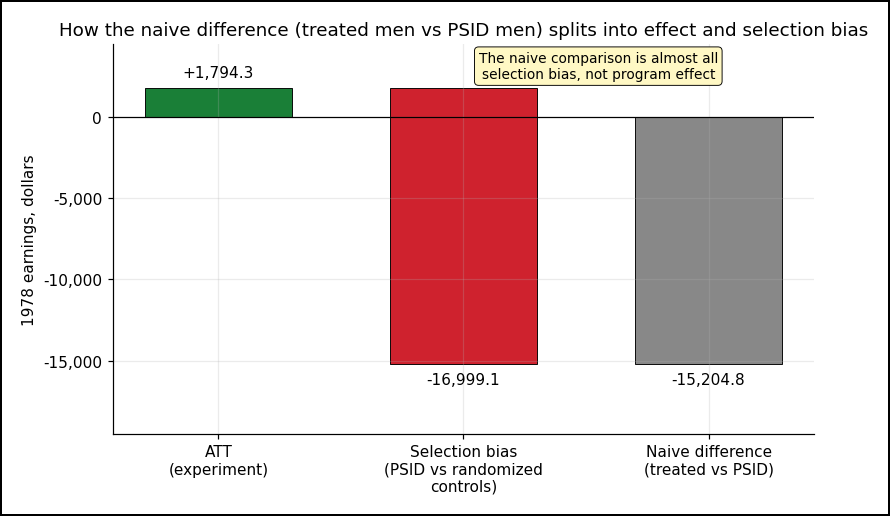

In [9]:
# Waterfall in dollars: the naive difference built from its two parts.
GREEN, RED = "#1a7f37", "#cf222e"  # increase = good, decrease = bad
steps = [("ATT\n(experiment)", att_exp), ("Selection bias\n(PSID vs randomized\ncontrols)", sel_bias)]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
level = 0.0
for i, (label, v) in enumerate(steps):
    ax.bar(i, v, bottom=level, color=GREEN if v > 0 else RED, width=0.6, edgecolor="black", linewidth=0.6)
    ax.text(i, level + v + (500 if v > 0 else -500), f"{v:+,.1f}", ha="center", va="bottom" if v > 0 else "top")
    level += v
ax.bar(len(steps), naive_psid, color=GREY, width=0.6, edgecolor="black", linewidth=0.6)
ax.text(len(steps), naive_psid - 500, f"{naive_psid:,.1f}", ha="center", va="top")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(steps) + 1), [s[0] for s in steps] + ["Naive difference\n(treated vs PSID)"])
ax.set_ylabel("1978 earnings, dollars")
ax.set_ylim(-19500, 4500)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_title("How the naive difference (treated men vs PSID men) splits into effect and selection bias")
ax.text(1.55, 2400, "The naive comparison is almost all\nselection bias, not program effect",
        ha="center", fontsize=9, bbox=dict(boxstyle="round", fc="#fff8c4", ec="black", lw=0.6))
plt.tight_layout()
plt.show()

**Conclusion:** of the naive (−$15,204.8), the program effect is an estimated +$1,794.3 and selection bias an estimated (−$16,999.1). Both rest on the randomized controls standing in for the treated men without the program, so both carry sampling error. The bias is so large that its whole 95% interval sits far below zero. The men who joined NSW would have earned roughly $17,000 less in 1978 than the PSID men **even without the program**.

**Caveat:** "selection bias" here is everything that separates the PSID men from the randomized controls, not only who they are. It also includes any difference in how earnings were recorded in the two sources. The data page does not say whether the two sources measured earnings the same way.

This bias comes from comparing all the treated men with all the PSID men, as they are. Later modules compare the treated men only with PSID men who looked like them before the program, which should make this bias much smaller.

**Hypothesis:** the bias comes from who the two groups are. Module 2 draws which "before" columns drive who joins and also drive earnings. Modules 3–5 adjust for them and test the hypothesis. The next step looks at the columns themselves.

### Step 4: where does the selection bias come from?

Compare the three groups (treated men, randomized controls, PSID men) on what was known **before** the program.

In [10]:
cols = {"age": "age", "education": "years of education", "black": "black (share)",
        "hispanic": "hispanic (share)", "married": "married (share)", "nodegree": "no degree (share)",
        "re74": "1974 earnings", "re75": "1975 earnings"}
bal = pd.DataFrame({
    "before the program": list(cols.values()),
    "NSW treated": [nsw_t[c].mean() for c in cols],
    "NSW randomized controls": [nsw_c[c].mean() for c in cols],
    "PSID men": [psid_c[c].mean() for c in cols],
})
fmt = {"age": "{:.1f}", "education": "{:.1f}", "re74": "{:,.1f}", "re75": "{:,.1f}"}
for c in ["NSW treated", "NSW randomized controls", "PSID men"]:
    bal[c] = [fmt.get(k, "{:.3f}").format(v) for k, v in zip(cols, bal[c])]
bal.loc[len(bal)] = ["zero 1975 earnings (share)"] + [f"{(g.re75 == 0).mean():.3f}" for g in (nsw_t, nsw_c, psid_c)]
show(bal)
print()
print(f"Age gap, PSID minus treated = {psid_c.age.mean():.1f} - {nsw_t.age.mean():.1f} = {psid_c.age.mean() - nsw_t.age.mean():.1f} years")
print(f"1975 earnings, PSID vs treated = {psid_c.re75.mean():,.1f} / {nsw_t.re75.mean():,.1f} = {psid_c.re75.mean() / nsw_t.re75.mean():.2f} times")

before the program          NSW treated  NSW randomized controls  PSID men
age                                25.8                     25.1      34.9
years of education                 10.3                     10.1      12.1
black (share)                     0.843                    0.827     0.251
hispanic (share)                  0.059                    0.108     0.033
married (share)                   0.189                    0.154     0.866
no degree (share)                 0.708                    0.835     0.305
1974 earnings                   2,095.6                  2,107.0  19,428.7
1975 earnings                   1,532.1                  1,266.9  19,063.3
zero 1975 earnings (share)        0.600                    0.685     0.100

Age gap, PSID minus treated = 34.9 - 25.8 = 9.0 years
1975 earnings, PSID vs treated = 19,063.3 / 1,532.1 = 12.44 times


**Observation:**
- The PSID men are a different population: 9.0 years older, mostly married (0.866 vs 0.189), and they earned 12.44 times as much in 1975 ($19,063.3 vs $1,532.1).
- 60.0% of the treated men earned nothing in 1975, against 10.0% of the PSID men.
- The treated and the randomized controls look alike on most rows, which is what randomization buys. Two rows stand out by eye: "no degree" (0.708 vs 0.835) and "hispanic" (0.059 vs 0.108).

Randomization balances groups *on average over many draws*, not exactly in one sample. The check below tests **all 8 rows**, not only the ones that caught the eye. With 8 rows, one usually looks uneven by pure chance, so testing only the ones that look uneven would find a "difference" too easily.

Both tests answer the same question: is the gap between the two groups bigger than chance alone would produce? They differ only in the kind of column:
- Welch t-test: for number columns (age, years of education, earnings). It compares the two groups' averages.
- Chi-square test: for yes/no columns (black, hispanic, married, no degree). It compares the two groups' shares.

Each test gives a p-value: the chance of seeing a gap at least this big if the lottery were fair. A small p-value means the gap is unlikely to be chance alone.

In [11]:
rows = []
for c, label in cols.items():
    if c in ("black", "hispanic", "married", "nodegree"):   # yes/no columns: chi-square test
        p, test = stats.chi2_contingency(pd.crosstab(exp.treat, exp[c])).pvalue, "chi-square"
    else:                                                   # numeric columns: Welch t-test
        p, test = stats.ttest_ind(nsw_t[c], nsw_c[c], equal_var=False).pvalue, "Welch t-test"
    rows.append({"before the program": label, "test": test, "p-value": f"{p:.4f}"})
show(pd.DataFrame(rows))
print()
print(f"Bonferroni threshold = 0.05 / {len(cols)} rows = {0.05 / len(cols):.5f}")

before the program  test          p-value
age                 Welch t-test   0.2659
years of education  Welch t-test   0.1502
black (share)       chi-square     0.7440
hispanic (share)    chi-square     0.1089
married (share)     chi-square     0.3936
no degree (share)   chi-square     0.0021
1974 earnings       Welch t-test   0.9819
1975 earnings       Welch t-test   0.3853

Bonferroni threshold = 0.05 / 8 rows = 0.00625


**Observation:**
- Only "no degree" falls below 0.05 (p = 0.0021). "Hispanic", the other row that looked uneven, has p = 0.1089: well within chance.
- "No degree" also passes the **Bonferroni correction**, the standard fix for testing several rows at once: divide 0.05 by the number of tests (0.05 / 8 = 0.00625), and count a row as unusual only below that. 0.0021 is below 0.00625.

**What it means:** with real randomization, a gap like this is still chance, just an unlucky draw. It does not mean the men chose their group. One more possible source: this subsample keeps only the men whose 1974 earnings are known, and that filter could have disturbed the original balance.

**Hypothesis:** it should bias the benchmark only a little. The two groups match closely on 1974 earnings ($2,095.6 vs $2,107.0), and their 1975 gap ($1,532.1 vs $1,266.9) is well within chance (p = 0.3853). Earlier earnings are usually the strongest predictor of later earnings. Module 3 tests this directly by adjusting the experimental estimate for "no degree".

### Step 5: does the PSID have look-alikes for the treated men? (overlap)

Selection bias can be removed, in principle, by comparing like with like: each treated man with PSID men who **looked the same** before the program. That only works where such PSID men exist. This is called **overlap**, or **positivity**: for every profile X of "before" columns that a treated man has, the chance of being untreated is above zero, written P(T = 0 | X) > 0.

The ATT is about the treated men only. So each treated man needs some PSID men who looked like him before the program, to compare him with. The real problem is a treated man with few or no PSID look-alikes, because then there is no one to compare him with. The opposite case doesn't matter: PSID men who look like no treated man (for example, men richer than every treated man) are simply left out.

Highest 1975 earnings among the 185 treated men = 25,142.2
Treated men, 95th percentile of 1975 earnings = 6,855.3
PSID men who earned more than every treated man = 680 of 2,490 = 27.3%

1975 earnings              NSW treated  PSID men  PSID men per treated man
0                                  111       249                      2.24
above 0 to 2,500                    32        47                      1.47
2,500 to 5,000                      22        78                      3.55
5,000 to 10,000                     15       252                     16.80
10,000 to highest treated            5     1,184                    236.80
above highest treated                0       680                       n/a

profile                                  NSW treated  PSID men
zero 1975 earnings                               111       249
zero 1975 earnings and unmarried                  95        35
zero 1975 earnings, unmarried and black           82        14


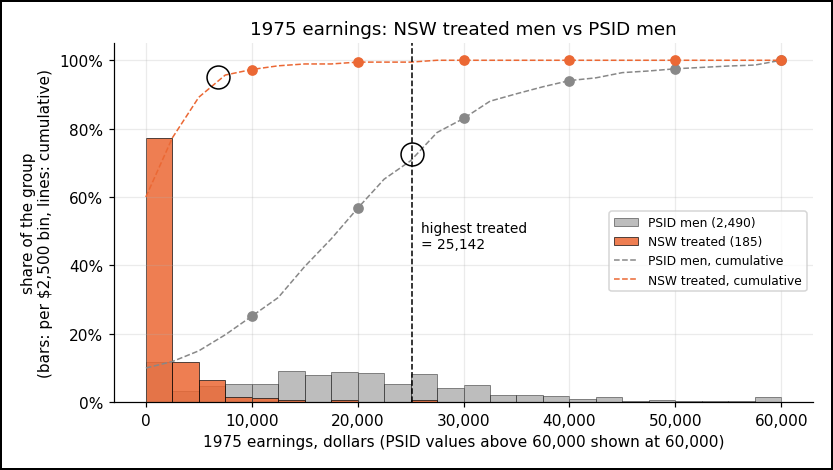

In [12]:
max_t = nsw_t.re75.max()
above = (psid_c.re75 > max_t).sum()
print(f"Highest 1975 earnings among the 185 treated men = {max_t:,.1f}")
print(f"Treated men, 95th percentile of 1975 earnings = {nsw_t.re75.quantile(0.95):,.1f}")
print(f"PSID men who earned more than every treated man = {above:,} of {len(psid_c):,} = {above / len(psid_c):.1%}")
print()

# How many PSID men are there for each treated man, in the treated men's own range?
edges = [-0.1, 0, 2500, 5000, 10000, max_t, np.inf]
labels = ["0", "above 0 to 2,500", "2,500 to 5,000", "5,000 to 10,000", "10,000 to highest treated", "above highest treated"]
n_t = pd.cut(nsw_t.re75, edges, labels=labels).value_counts().reindex(labels)
n_p = pd.cut(psid_c.re75, edges, labels=labels).value_counts().reindex(labels)
show(pd.DataFrame({"1975 earnings": labels, "NSW treated": [f"{v:,}" for v in n_t.values], "PSID men": [f"{v:,}" for v in n_p.values],
                   "PSID men per treated man": [f"{p / t:.2f}" if t else "n/a" for p, t in zip(n_p.values, n_t.values)]}))
print()

# The typical treated man has several traits at once. Count look-alikes on more columns together.
profiles = [
    ("zero 1975 earnings", lambda d: d.re75 == 0),
    ("zero 1975 earnings and unmarried", lambda d: (d.re75 == 0) & (d.married == 0)),
    ("zero 1975 earnings, unmarried and black", lambda d: (d.re75 == 0) & (d.married == 0) & (d.black == 1)),
]
show(pd.DataFrame([{"profile": name, "NSW treated": f(nsw_t).sum(), "PSID men": f(psid_c).sum()} for name, f in profiles]))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
bins = np.arange(0, 62500, 2500)
share = lambda s: np.full(len(s), 1 / len(s))  # each man counts 1/n, so bars are shares of his group
psid75 = psid_c.re75.clip(upper=60000)
ax.hist(psid75, bins=bins, weights=share(psid_c), alpha=0.55, color=GREY, edgecolor="black", linewidth=0.5, label="PSID men (2,490)")
ax.hist(nsw_t.re75, bins=bins, weights=share(nsw_t), alpha=0.85, color=ORANGE, edgecolor="black", linewidth=0.5, label="NSW treated (185)")

# Cumulative share of each group earning at most x, on the same y axis.
cum = lambda s, x: (s <= x).mean()
tens = np.arange(10000, 60001, 10000)
for s, color, name in [(psid75, GREY, "PSID men, cumulative"), (nsw_t.re75, ORANGE, "NSW treated, cumulative")]:
    ax.plot(bins, [cum(s, x) for x in bins], ls="--", lw=1, color=color, label=name)
    ax.plot(tens, [cum(s, x) for x in tens], "o", ms=6, color=color)

# Circle the two named points: 95% of treated men earned under 6,855, and 72.7% of PSID men earned at most the highest treated man.
q95 = nsw_t.re75.quantile(0.95)
for x, y in [(q95, 0.95), (max_t, 1 - above / len(psid_c))]:
    ax.plot(x, y, "o", ms=15, mfc="none", mec="black", mew=1)

ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.axvline(max_t, color="black", ls="--", lw=1)
ax.text(max_t + 800, 0.45, f"highest treated\n= {max_t:,.0f}", fontsize=9)
ax.set_xlabel("1975 earnings, dollars (PSID values above 60,000 shown at 60,000)")
ax.set_ylabel("share of the group\n(bars: per $2,500 bin, lines: cumulative)")
ax.set_title("1975 earnings: NSW treated men vs PSID men")
ax.legend(loc="center right", bbox_to_anchor=(1, 0.42), fontsize=8)
plt.tight_layout()
plt.show()

**Observation:**
- The treated men's highest 1975 earnings, $25,142.2, is an outlier: 95% of them earned under $6,855.3.
- 680 PSID men (27.3%) earned more than every treated man. For the ATT they carry no information and can be dropped.
- On 1975 earnings alone, overlap looks fine where the treated men are: 249 PSID men with zero earnings for 111 treated men (2.24 per treated man).
- It thins fast as columns are combined. Zero earnings, unmarried and black is the profile of 82 treated men, and only 14 PSID men share it.

**Conclusion:** the PSID data does have look-alikes for the typical treated man, but very few once several "before" columns are combined. Methods that compare like with like (Modules 3–5) will lean on a small number of PSID men, or extrapolate from men who do not look like the treated. Module 4 measures this with a propensity score, which combines all the columns at once.

## The assumptions every later module rests on

Two assumptions are needed **for any method**, including the experiment:
- **SUTVA (stable unit treatment value assumption).** One man's outcome does not depend on whether *other* men were treated (no interference), and "treated" means the same thing for everyone (one version of the treatment). It would fail if, for example, a man trained by the program got a job that an untrained man from the lottery, in the same city, would otherwise have got. Then the program would also lower the untrained men's earnings, and even the experiment's answer would come out too high.
- **Consistency.** The observed outcome of a treated man **is** his Y(1). This is the formula Y = T × Y(1) + (1 − T) × Y(0) above.

Without randomization, each method needs **its own** reason to believe the missing Y(0) can be filled in:

| Module | Method | What it assumes instead of randomization |
|---|---|---|
| 2 | DAGs (directed acyclic graphs) | nothing: it gives no answer of its own. It's a diagram of what causes what, used to choose which "before" columns Modules 3–5 should adjust for |
| 3–5 | regression, matching, weighting | **unconfoundedness**: after accounting for the measured "before" columns, who joined is as good as random. Plus **overlap**: for every treated profile, untreated men exist |
| 6 | difference-in-differences | **parallel trends**: without the program, both groups' earnings would have *changed* by the same amount |
| 7 | instrumental variables | an **instrument** that moves treatment, and moves the outcome **only** through treatment |
| 8 | regression discontinuity | units just either side of a **cutoff** are alike |
| 9 | synthetic control | a **weighted mix** of untreated units tracks the treated unit before treatment |

Module 10 asks how wrong each answer gets if its assumption is partly false.

## Exercise — a different comparison group

LaLonde also built a second comparison group from the CPS (Current Population Survey, a monthly US labour survey): 15,992 men.

1. Compute the naive difference: NSW treated vs CPS men.
2. Split it into the ATT and selection bias, using the randomized controls as E[Y(0) | T = 1].
3. Is the CPS group a better or worse comparison group than the PSID? Say why, using numbers.

Write your answer first, then run the next cell.

In [13]:
cps = common.load_lalonde("cps")
cps_c = cps[cps.treat == 0]
m_cps = cps_c.re78.mean()
naive_cps = m_t - m_cps
sel_cps = m_c - m_cps
print(f"E[Y(0) | T = 1], mean 1978 earnings the treated men ({len(nsw_t)} men) would have had without the program, "
      f"estimated by the mean 1978 earnings of the randomized controls ({len(nsw_c)} men) = {m_c:,.1f}")
print(f"E[Y(0) | T = 0], mean 1978 earnings of the CPS men ({len(cps_c):,} men) = {m_cps:,.1f}")
print(f"Naive difference = (E[Y(1) | T = 1] - E[Y(0) | T = 1]) + (E[Y(0) | T = 1] - E[Y(0) | T = 0]) = "
      f"({m_t:,.1f} - {m_c:,.1f}) + ({m_c:,.1f} - {m_cps:,.1f}) = {naive_cps:,.1f}")
print(f"ATT ({len(nsw_t)} men) = E[Y(1) | T = 1] - E[Y(0) | T = 1] = {m_t:,.1f} - {m_c:,.1f} = {att_exp:,.1f}")
print(f"Selection bias = E[Y(0) | T = 1] - E[Y(0) | T = 0] = {m_c:,.1f} - {m_cps:,.1f} = {sel_cps:,.1f}")
print()
print(f"Mean 1975 earnings, CPS men ({len(cps_c):,} men) = {cps_c.re75.mean():,.1f}")
print(f"Mean 1975 earnings, PSID men ({len(psid_c):,} men) = {psid_c.re75.mean():,.1f}")
print(f"Mean 1975 earnings, treated men ({len(nsw_t)} men) = {nsw_t.re75.mean():,.1f}")
print()
print(f"Selection bias, CPS vs PSID = 1 - {abs(sel_cps):,.1f} / {abs(sel_bias):,.1f} = {1 - sel_cps / sel_bias:.1%} smaller")
print(f"1975 earnings, CPS vs treated = {cps_c.re75.mean():,.1f} / {nsw_t.re75.mean():,.1f} = {cps_c.re75.mean() / nsw_t.re75.mean():.2f} times")

E[Y(0) | T = 1], mean 1978 earnings the treated men (185 men) would have had without the program, estimated by the mean 1978 earnings of the randomized controls (260 men) = 4,554.8
E[Y(0) | T = 0], mean 1978 earnings of the CPS men (15,992 men) = 14,846.7
Naive difference = (E[Y(1) | T = 1] - E[Y(0) | T = 1]) + (E[Y(0) | T = 1] - E[Y(0) | T = 0]) = (6,349.1 - 4,554.8) + (4,554.8 - 14,846.7) = -8,497.5
ATT (185 men) = E[Y(1) | T = 1] - E[Y(0) | T = 1] = 6,349.1 - 4,554.8 = 1,794.3
Selection bias = E[Y(0) | T = 1] - E[Y(0) | T = 0] = 4,554.8 - 14,846.7 = -10,291.9

Mean 1975 earnings, CPS men (15,992 men) = 13,650.8
Mean 1975 earnings, PSID men (2,490 men) = 19,063.3
Mean 1975 earnings, treated men (185 men) = 1,532.1

Selection bias, CPS vs PSID = 1 - 10,291.9 / 16,999.1 = 39.5% smaller
1975 earnings, CPS vs treated = 13,650.8 / 1,532.1 = 8.91 times


**Answer:**
1. The naive difference against the CPS men is (−$8,497.5).
2. It splits into the ATT, +$1,794.3, and selection bias, (−$10,291.9).
3. **Less bad than the PSID, still far from usable.** The selection bias is 39.5% smaller: (−$10,291.9) vs (−$16,999.1). That fits the CPS men having earned less before the program ($13,650.8 in 1975 vs $19,063.3 for the PSID men). But they still earned 8.91 times as much as the treated men ($1,532.1), so the naive comparison still has the wrong sign.

The lesson: no off-the-shelf comparison group removes selection bias by itself. Modules 3–5 try to remove it by adjusting for the "before" columns.

## Interview angle

> "Users who adopted feature X retain 12 points better than users who didn't. Did X cause it?"

A strong answer uses this module directly:
- The 12 points are the **naive difference** = (effect of X on adopters, the ATT) + (selection bias).
- Selection bias here is very likely **positive**: users who adopt a feature are usually already more engaged, so they would retain better even without it. So the 12 points probably **overstate** the effect.
- Name the estimand: "the effect on adopters" (ATT) is not "the effect of pushing X to everyone" (ATE). The second needs its own evidence.
- Then name the way out: an experiment if possible (the A/B Testing Playbook): randomly split users into two groups, give feature X to one group only, and compare how many in each group keep using the app. Otherwise, one of Modules 3–9, with its assumption stated.

## Key takeaways

- **Each person has two potential outcomes, Y(1) and Y(0), and only one is ever seen.** No individual effect can be computed, so causal inference estimates averages.
- **Say which average.** ATE (everyone), ATT (the treated), ATC (the untreated) differ when effects vary *with who gets treated*: 1.667, 2.667 and 0.667 in the six-person example.
- **Naive difference = ATT + selection bias.** It is an identity, derived by adding and subtracting E[Y(0) | T = 1].
- **On real data the bias can swamp the effect.** NSW vs PSID: (−$15,204.8) naive = +$1,794.3 effect + (−$16,999.1) selection bias.
- **Randomization sets selection bias to zero on average,** not exactly: even the NSW experiment is unbalanced on "no degree" (0.708 vs 0.835).
- **Without randomization, every method trades it for an assumption.** Modules 3–5 need unconfoundedness and overlap. For the ATT, overlap means look-alikes for every treated man, and in the PSID data they are thin: 14 PSID men share the profile of 82 treated men (zero 1975 earnings, unmarried, black).